# Part 1: Do French, Spanish and Turkish people differ genetically?

Principal component analysis (PCA, via SVD) of 777 people genotyped at 20,000 genetic markers (SNPs).

**Authors:** Ido Shalom, Daniel Rodan

## PCA of the genotype data

### Section A

Number of explanatory variables: 20000
Number of observations: 777


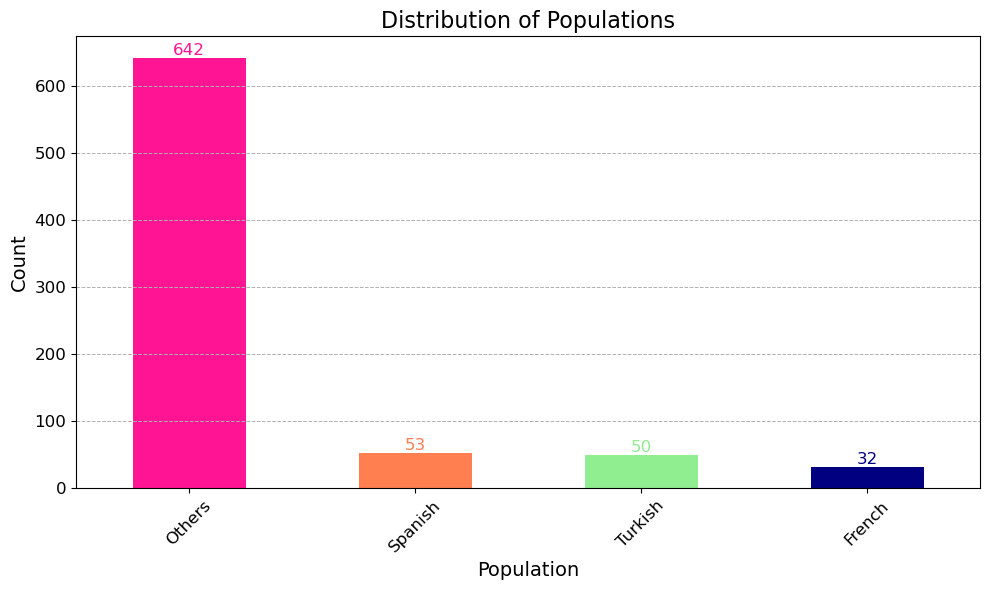

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Define the paths to the files
geno_path = 'data/geno'
ind_path = 'data/ind'
snp_path = 'data/snp'

# Load the data
geno = pd.read_csv(geno_path, header=None)
ind = pd.read_csv(ind_path, header=None, names=['Population'])
snp = pd.read_csv(snp_path, header=None, names=['SNP'])

# Determine the number of explanatory variables and observations
num_explanatory_variables = geno.shape[1]
num_observations = geno.shape[0]

# Show a distribution of the dependent variable
population_distribution = ind['Population'].value_counts()

# Print the results
print(f'Number of explanatory variables: {num_explanatory_variables}')
print(f'Number of observations: {num_observations}')

# Map the original population labels to the desired labels
label_mapping = {
    'Spanish.HO_PCA': 'Spanish',
    'Turkish.HO_PCA': 'Turkish',
    'French.HO_PCA': 'French',
    'Unknown': 'Others'
}

# Apply the mapping to the population data
ind['Population'] = ind['Population'].map(label_mapping)
population_distribution = ind['Population'].value_counts()

# Define colors for each population group
colors = {
    'Spanish': 'coral',
    'Turkish': 'lightgreen',
    'French': 'navy',
    'Others': 'deeppink'
}

# Plot the distribution
plt.figure(figsize=(10, 6))
population_distribution.plot(kind='bar', color=[colors[label] for label in population_distribution.index])
plt.title('Distribution of Populations', fontsize=16)
plt.xlabel('Population', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.xticks(rotation=45, fontsize=12)
plt.yticks(fontsize=12)
plt.grid(axis='y', linestyle='--', linewidth=0.7)
plt.tight_layout()

# Annotate bars with counts
for i, (label, count) in enumerate(population_distribution.items()):
    plt.text(i, count + 5, str(count), ha='center', fontsize=12, color=colors[label])

plt.show()

### Section B

In [7]:
# Identify and Remove Low Variance Variables
variances = geno.var(axis=0)
low_variance_cols = variances[variances == 0].index
geno_cleaned = geno.drop(columns=low_variance_cols)

# Print the number of SNPs removed
print(f'Number of SNPs with zero variance removed: {len(low_variance_cols)}')
print(f'Number of remaining SNPs: {geno_cleaned.shape[1]}')

# Normalize the Data
geno_normalized = (geno_cleaned - geno_cleaned.mean()) / geno_cleaned.std()

Number of SNPs with zero variance removed: 935
Number of remaining SNPs: 19065


**Are there explanatory variables that we would like to get rid of at this stage?** 

We chose to remove all the explanatory variables (columns) with zero variance.


Because these columns have identical values for all items, they do not provide any useful information for distinguishing between the observations and populations in the analysis.

### Section C

In [8]:
# Perform SVD
U, S, VT = np.linalg.svd(geno_normalized, full_matrices=False)

# Dimensions of the components
print(f'Dimensions of U: {U.shape}')
print(f'Dimensions of S: {S.shape}')
print(f'Dimensions of VT: {VT.shape}')

Dimensions of U: (777, 777)
Dimensions of S: (777,)
Dimensions of VT: (777, 19065)


**What is the meaning of each component?**

- The U matrix contains the left singular vectors, each column representing a principal component in the space of observations (individuals). It captures how each individual can be expressed in terms of these principal components. Essentially, it provides a new set of coordinates for the individuals based on the principal components.

- The S matrix contains the singular values, which represent the amount of variance captured by each principal component. They indicate the significance of each principal component in explaining the data's variance.

- The Vᵀ matrix contains the right singular vectors, each row representing a principal component in the space of variables (SNPs). It captures how each variable can be expressed in terms of these principal components. This matrix helps in understanding the relationship and importance of each SNP within the principal component space.

### Section D

In [9]:
import numpy as np
import pandas as pd

# Define the column names
column_names = ['SNP', 'Chromosome', 'Frequent_Allele', 'Rare_Allele']

# Read the CSV file 
snp = pd.read_csv(snp_path, header=None)
snp.columns = column_names

# Extract loadings for the first principal component
first_pc_loadings = VT[0]

# Identify the indices of the ten most influential genetic markers
most_influential_indices = np.argsort(np.abs(first_pc_loadings))[-10:][::-1]

# Map these indices to SNP names using the snp DataFrame
most_influential_snps = snp.iloc[most_influential_indices]

# Display the results
print("The ten most influential genetic markers:")
print(most_influential_snps[['SNP', 'Chromosome', 'Frequent_Allele', 'Rare_Allele']])


The ten most influential genetic markers:
              SNP Chromosome Frequent_Allele Rare_Allele
11608  rs78030696         10               G           A
2548     rs906815          2               G           A
13351  rs56005168         11               A           G
7738     rs831481          6               G           A
2550    rs9308692          2               T           C
1781    rs7601972          2               G           A
9993    rs1362889          8               G           A
6585    rs9293356          5               T           C
1474     rs977146          1               A           G
2124      rs42785          2               A           G




**Did you find a SNP of significance?**

The SNP rs906815 is located on chromosome 2 and has been linked to rheumatoid artritis(RA). It is included in polygenic risk scores (PRS) for predicting the diease. This SNP is involved in regulatory regions like transcription factor binding sites and miRNA binding ites. It is significant for developing personalized medicine approaches fr RA. However, there is no specific information available about its prevalence in particular populations.

### Section E

**How each individual is projected on the first two PCs?**

Each individual is projected onto the first two principal components by multiplying the individual's data (in terms of SNP values) with the corresponding principal component vectors.


This transforms the data from the high-dimensional SNP space to a lower-dimensional space defined by the first two principal components.

In [10]:
# Extract loadings for the first two principal components
PC1 = VT[0, :]
PC2 = VT[1, :]

# Project the data onto the first two principal components
proj_PC1 = np.dot(geno_normalized, PC1)
proj_PC2 = np.dot(geno_normalized, PC2)

**What is the dimension obtained for each Individual?**

Each individual is represented in a 2-dimensional space (PC1, PC2).

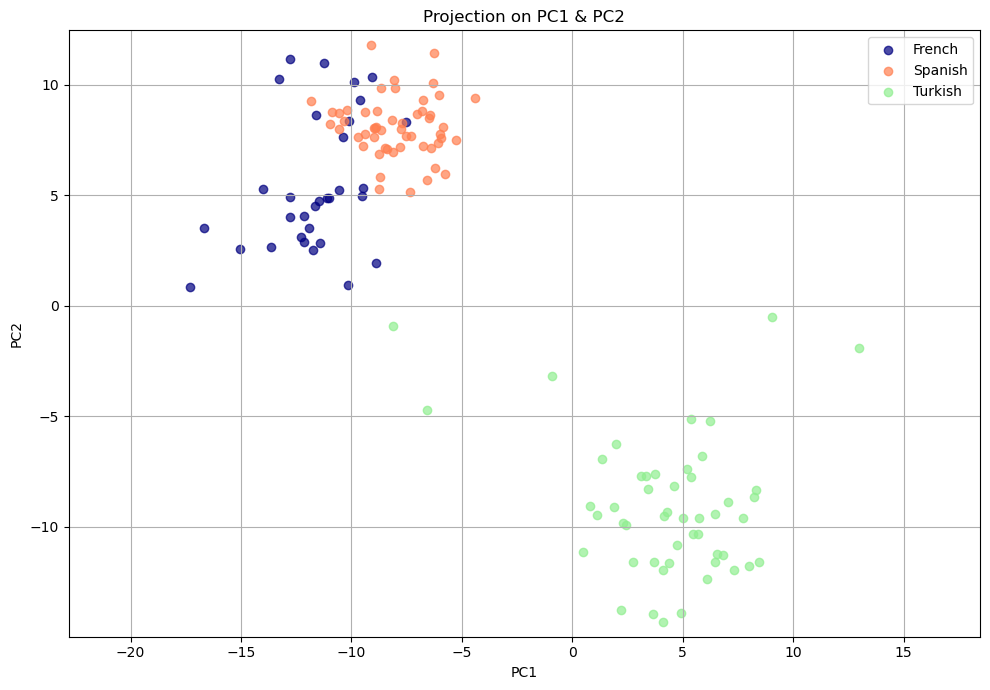

In [11]:
# Create a DataFrame with the projections and the population labels
projections_df = pd.DataFrame({
    'PC1': proj_PC1,
    'PC2': proj_PC2,
    'Population': ind['Population']
})

# Define the populations of interest
our_populations = ['French', 'Spanish', 'Turkish']

# Filter the DataFrame to include only the Turkish, Spanish, and French populations
filtered_projections_df = projections_df[projections_df['Population'].isin(our_populations)]

# Plotting the projections on the first and second principal components for the filtered populations
plt.figure(figsize=(10, 7))

# Scatter plot for the projections with different colors for each population
colors = {'French': 'navy', 'Spanish': 'coral', 'Turkish': 'lightgreen'}
for population in filtered_projections_df['Population'].unique():
    indices = filtered_projections_df[filtered_projections_df['Population'] == population]
    plt.scatter(indices['PC1'], indices['PC2'], alpha=0.7, label=population, color=colors[population])

plt.title('Projection on PC1 & PC2')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.grid(True)
plt.legend()
plt.axis('equal')
plt.tight_layout()
plt.show()

**Do you manage to visually separate the populations?**

The populations can be visually separated in the plot. The French (navy) and Spanish (coral) populations cluster closely together, while the Turkish (light green) population forms a distinct, separate cluster.

However, it is important to note that without the different colors for each population, we are not quite sure if we would be able to distinguish between French and Spanish.

This visual separation indicates that the first two principal components capture significant variance between these populations.

**Is there a connection between the geographical proximity of the populations and your results?**

There is a connection between geographical proximity and the results.

The French and Spanish populations, which are geographically closer to each other, are more similar and hence form overlapping clusters in the PCA plot.

The Turkish population, which is geographically farther, forms a distinct cluster, reflecting greater genetic variation relative to the French and Spanish populations.

### Section F

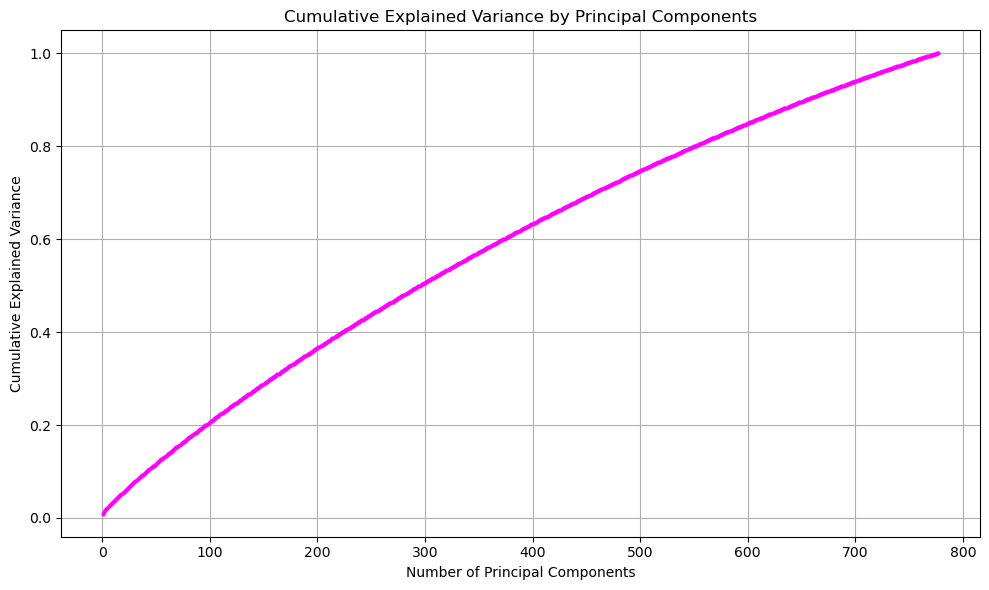

Variance recovered by the initial 2 eigencomponents: 1.33%


In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Perform SVD
U, S, VT = np.linalg.svd(geno_normalized, full_matrices=False)

# Total explained variance from PCs
explained_variance = (S**2) / np.sum(S**2)
cumulative_explained_variance = np.cumsum(explained_variance)

# Plotting the cumulative explained variance 
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(cumulative_explained_variance) + 1), cumulative_explained_variance, 'o', markersize=2, color='magenta')
plt.title('Cumulative Explained Variance by Principal Components')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.grid(True)
plt.tight_layout()
plt.show()

# Variance recovered by the initial 2 eigencomponents
variance_2_components = cumulative_explained_variance[1] * 100
print(f'Variance recovered by the initial 2 eigencomponents: {variance_2_components:.2f}%')

**How much variance is recovered by the initial 2 eigencomponents?**

Based on the plot and the calculation, the initial 2 eigencomponents recover approximately 1.33% of the total variance.

**Does this figure surprise you in light of the separation you presented in the previous section?**

This figure might be surprising given the clear separation observed in the PCs scatter plot.

It suggests that while the first two components capture significant information for distinguishing the specific populations studied (French, Spanish, and Turkish), they do not capture the majority of the total variance in the data.

It means that somehow the 2 PCs were enough to give us a relatively clear distinction between the populations despite using so little of the total variance.




### Section G

In [13]:
# Number of eigencomponents needed to explain 50% variance
num_components = np.argmax(cumulative_explained_variance >= 0.5) + 1
print(f'Number of components to explain at least 50% variance: {num_components}')

# Reconstruct the data 
U_reduced = U[:, :num_components]
S_reduced = np.diag(S[:num_components])
VT_reduced = VT[:num_components, :]
reconstructed_data = np.dot(U_reduced, np.dot(S_reduced, VT_reduced))

# Calculate the reconstruction error using the Frobenius norm
reconstruction_error = np.linalg.norm(geno_normalized - reconstructed_data, 'fro')
print(f'Reconstruction error: {reconstruction_error:.2f}')

Number of components to explain at least 50% variance: 296
Reconstruction error: 2716.68


### Section H

**What is the Research Question?**

The research question aims to understand the genetic variation among individuals from different populations by analyzing Single Nucleotide Polymorphisms (SNPs) using Principal Component Analysis (PCA) and Singular Value Decomposition (SVD).


**What are the Data We Work With and How is Each of Them Relevant to the Research Question?**

- ***geno:*** This dataset contains the genetic information for 777 individuals across 20,000 SNPs. Each entry in the matrix represents the count of the common allele for a specific SNP in an individual. This data is crucial for performing PCA and SVD to analyze genetic variation and population structure.

- ***ind:*** This dataset includes the population labels for each individual (French, Spanish, Turkish, and others). It is essential for interpreting the results of the PCA by linking the genetic data to specific populations.

- ***snp:*** This dataset provides details about each SNP, including its name, chromosome location, and the common and rare alleles. This information is important for understanding the genetic markers used in the analysis and their potential significance in the genetic differences observed between populations.

**What are the contributions of SVD decomposition that helped examine the scientific question?**

SVD helped simplify the complex genetic data by reducing its dimensions, making it easier to analyze and visualize key patterns. It identified the principal components that capture the most variance, highlighting the important genetic variations.

Furthermore, it enabled us to reconstruct the data, helping us measure how well the reduced components represent the original information.

**what new information did we provide with its help?**

- We found clear genetic differences between French, Spanish, and Turkish populations.
 
- The first two components only explained a small part of the variance, showing the complexity of genetic data.

- We discovered that 296 components are needed to explain 50% of the variance, indicating that genetic variation is spread across many dimensions.

- The reconstruction error helped us understand the trade-off between reducing dimensions and retaining important genetic information.